In [1]:
%load_ext autoreload
%autoreload 2

In [67]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
from collections import Counter
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from langdetect import detect, DetectorFactory

from src.features import limpiar_features_no_necesarias, multi_binarizer_format, multi_binarizer_genre, transformar_target_a_estrellas, es_parte_de_saga, normalize_format, extraer_generos_libro, detectar_language_code, one_hot_language, generar_embeddings_pca, primer_tiene_role_vacio, extraer_autor_principal
from src.graficos import plot_boxplot_rating_por_genero, plot_generos_mas_frecuentes, plot_rating, plot_rating_por_genero, plot_stars, plot_boxplot_rating, plot_cantidad_generos_por_libro, plot_boxplot_rating_por_formato, plot_boxplot_rating_por_is_series, plot_scatte_rating_por_num_pages, plot_scatte_rating_por_publication_year, plot_boxplot_rating_por_autor_frecuent, plot_correlacion_features, plot_boxplot_rating_por_cant_generos
from src.utils import fusionar_libros
from src.splitting import split_estratificado_autor

## 1. Comienzo por filtrar el dataset:

### 1.1 Primero saco las muestras de paises non-US:

In [3]:
# chunks = pd.read_json("goodreads_books.json", lines=True, chunksize=100_000)

# us_list = []
# for chunk in chunks:
#     us_list.append(chunk[chunk["country_code"] == "US"])

# df_us = pd.concat(us_list, ignore_index=True)
# print(df_us.shape)


### 1.2 Ahora me tengo que quedar nomas con los libros que son en ingles:

Consideramos los libros en ingles los que tienen "languade_code" = ["en", "eng", "en-US", "en-GB", "en-CA", "enm", "ang", "sco", "gem"]

Las ultimas 4 opciones son ingles, pero antiguos (afectara en el rating del libro?... Acaso como a las personas de hoy en dia les cosatara mas atenderlo y por eso le daran bajo rating?...)

Tambien me quedo con las muestras con ese valor NaN, porque aun no podemos decidir si descartarlos o no.

In [4]:
valid_langs = {"en", "eng", "en-us", "en-gb", "en-ca", "enm", "ang", "sco", "gem"}
# lang = df_us["language_code"].fillna("").str.strip().str.lower()
# df_us_eng = df_us[lang.isin(valid_langs) | (lang == "")]
# print(df_us_eng.shape)

Lo guardo en un json:

In [5]:
# import json
# output_path = "goodreads_us_english.json"
# chunk_size = 10000
# with open(output_path, "w", encoding="utf-8") as f:
#     for start in range(0, len(df_us_eng), chunk_size):
#         chunk = df_us_eng.iloc[start:start + chunk_size]
#         records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
#         for record in records:
#             json.dump(record, f, ensure_ascii=False)
#             f.write("\n")
# print("Guardado en", output_path)

Ahora abro el nuevo archivo que acabo de crear, asi trabajo sobre ese:

In [6]:
chunks2 = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks2:
    chunk_list.append(chunk)

df_us_en = pd.concat(chunk_list, ignore_index=True)
print(df_us_en.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

(1925872, 29)


In [7]:
#pd.set_option('display.max_columns', None)
#pd.set_option('display.width', None)
#
##otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
##tardo aprox 3min14s en correr
#K = 100_000
#sample = []
#
#with open("goodreads_us_english.json", encoding="utf8") as f:
#    for i, line in enumerate(f):
#        obj = json.loads(line)
#
#        if i < K:
#            sample.append(obj)
#        else:
#            j = random.randint(0, i)
#            if j < K:
#                sample[j] = obj
#
#df_us_en = pd.DataFrame(sample)
#
#print(df_us_en.shape)
#print(df_us_en.head())
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

Primer filtrado:


Lo hacemos para reducir el tiempo de computo en las siguientes secciones.

Las decisiones fueron tomadas en base a analices que se hacen en secciones posteriores.

In [8]:
df_us_en = df_us_en[["text_reviews_count", "series", "language_code", "popular_shelves", "average_rating", "similar_books", "description", "format", "publication_year", "ratings_count", "title", "authors", "publisher", "num_pages"]]

In [9]:
# df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce')
# df_us_en = df_us_en.dropna(subset=["average_rating"]) #Eliminamos todas las muetsras que tienen avergae_rating = NaN o = None
# df_us_en["estrellas"] = transformar_target_a_estrellas(df_us_en["average_rating"])
# if "format_group" not in df_us_en.columns:
#     df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)
# df_us_en = df_us_en.drop(columns = ["format"]) 

# #is_series: feature binaria, true si es parte de una saga
# df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
# df_us_en = df_us_en.drop(columns = ["series"]) 

# df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
# df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"],errors='coerce')

In [10]:
#Las features "publication_year" y "num_pages" presetan valores NaN y algunos registros con valores extremos (ilogicos). 
#Como creemos que no hay una estrategia de imputacion que permita estimar esos valores de forma confiable y acorde a cada muestra en particular
#(la media o mediana no tendrian mucho sentido en estos casos), decidimos quedarnos solamente con las muestras que poseen años de publicacion 
#comprendidos entre 1440 (comienzo de la impresion) y 2026, y cantidad de paginas entre 1 y 10000. Este filtrado elimino simultaneamente aquellos 
#datos que poseian algun valor faltantes para alguna de estas dos caracterisitcas (este porcentaje de muestras es insignificante en comapracion
# a la cantidad total de datos que se posee).

# mask = df_us_en['publication_year'].between(1440, 2026) & df_us_en["num_pages"].between(1, 10000) #1440 es el año en que se invento la impresion
# df_us_en = df_us_en[mask]

In [11]:
# import json
# output_path22 = "goodreads_us_english_primer_filtrado.json"
# chunk_size22 = 10000
# with open(output_path22, "w", encoding = "utf-8") as f:
#     for start in range(0, len(df_us_en), chunk_size22):
#         chunk = df_us_en.iloc[start:start + chunk_size22]
#         records = chunk.where(pd.notna(chunk), None).to_dict(orient = "records")
#         for record in records:
#             json.dump(record, f, ensure_ascii = False)
#             f.write("\n")
# print("Guardado en", output_path22)

Abro el nuevo json con este primer filtrado:

In [12]:
# chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)

# chunk_list33 = []
# for chunk in chunks33:
#     chunk_list33.append(chunk)

# df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
# print(df_us_en_1_filtro.shape)
# #TODO: comentario de clara para clara: comentar este bloque antes de correr

## 2. Reorganizo valores de features (breve inicio del preprocesamiento):

## 3. Analizo features (EDA):

### 3.1 Analisando el target

In [13]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce') 
print(df_us_en["average_rating"].isna().sum())
print(df_us_en["average_rating"].max())
print(df_us_en["average_rating"].min())

6
5.0
0.0


En este sample, hay XX libros sin rating. Corresponde al XXX%. Podemos eliminar esos libros. Notamos aparte que no hay outliers. --> SIGUE EN PIE ESTO CON TODO EL DATASET???

In [14]:
#ELIMINAR EL TARGET CON NAN
df_us_en = df_us_en.dropna(subset=["average_rating"]) #Eliminamos todas las muetsras que tienen avergae_rating = NaN o = None
target_regresion = df_us_en["average_rating"]
df_us_en["estrellas"] = transformar_target_a_estrellas(target_regresion)

In [15]:
df_us_en["average_rating"].describe()

count    1.925866e+06
mean     3.885112e+00
std      5.304168e-01
min      0.000000e+00
25%      3.650000e+00
50%      3.920000e+00
75%      4.170000e+00
max      5.000000e+00
Name: average_rating, dtype: float64

Como lo van a confirmar los graficos mas adelante, la mayoria de ratings se encuentran entre 3.5 y 4.5. 

In [16]:
df_us_en["estrellas"].value_counts(normalize=True).sort_index()

estrellas
0    0.002874
1    0.001938
2    0.010903
3    0.142532
4    0.765295
5    0.076458
Name: proportion, dtype: float64

El desbalanceo de clases se hace aun mas presente en el target para clasificacion.

In [17]:
target_clasificacion_balanceado = pd.qcut(df_us_en["average_rating"], q=5)
print(target_clasificacion_balanceado.value_counts().sort_index())

average_rating
(-0.001, 3.57]    395416
(3.57, 3.82]      383709
(3.82, 4.0]       396414
(4.0, 4.25]       383064
(4.25, 5.0]       367263
Name: count, dtype: int64


Esta estrategia permitiria mantener 5 clases balanceadas, pero perdemos la interpretabilidad de las 5 estrellas. 

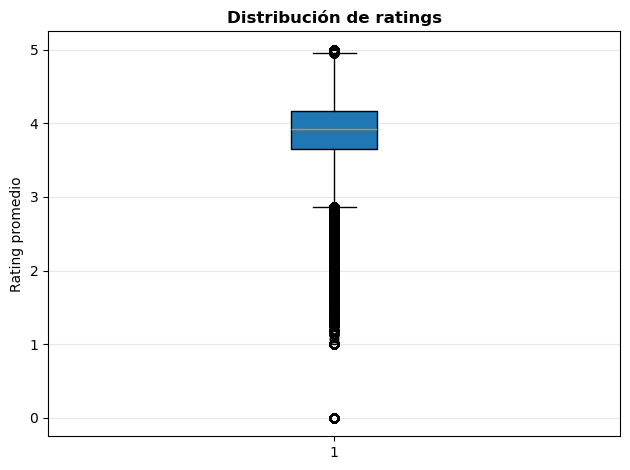

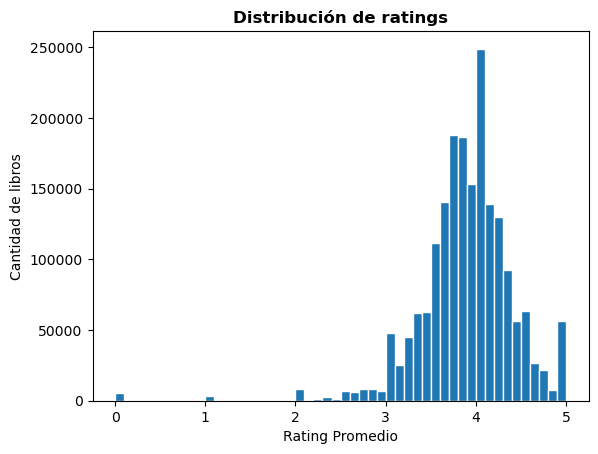

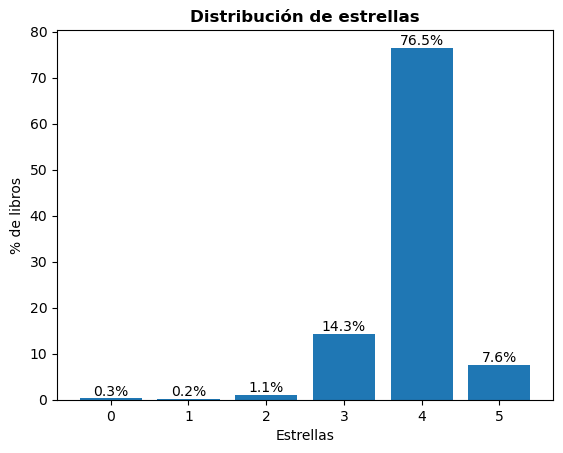

In [18]:
plot_boxplot_rating(df_us_en)
plot_rating(df_us_en)
plot_stars(df_us_en)

La mayoria de los ratings se encuentra entre 3.5 y 4.5. Este desbalance se hace mas presente al pasar el rating a estrellas. 

In [19]:
missing_summary = pd.DataFrame({
    "missing_count": df_us_en.isna().sum(),
    "missing_pct": df_us_en.isna().mean() * 100,
    "empty_string_count": (df_us_en == "").sum()
})
print(missing_summary)

                    missing_count  missing_pct  empty_string_count
text_reviews_count              0          0.0                   0
series                          0          0.0                   0
language_code                   0          0.0             1059663
popular_shelves                 0          0.0                   0
average_rating                  0          0.0                   0
similar_books                   0          0.0                   0
description                     0          0.0              351418
format                          0          0.0              583911
publication_year                0          0.0              548371
ratings_count                   0          0.0                   0
title                           0          0.0                   7
authors                         0          0.0                   0
publisher                       0          0.0              605475
num_pages                       0          0.0              70

### 3.2 Veo cuantas muestras tienen el laguage_code incompleto:

In [20]:
missing = df_us_en["language_code"].isna().sum() #Aplica para NaN y None
empty_str = (df_us_en["language_code"] == "").sum()
print("NaN:", missing)
print("Cadena vacía:", empty_str)
print("Total vacío:", missing + empty_str)

NaN: 0
Cadena vacía: 1059663
Total vacío: 1059663


Tiene sentido que hayan 0 NaN, porque cuando adquirimos las muestras para armar el dataset actual, convertimos los NaN en stirngs vacios (para veitar warnings)

### 3.3 ¿El formato del libro tiene alguna relacion con el rating?

En primer lugar, tenemos que agrupar las diferentes redacciones de cada formato:

In [21]:
# format_uniques = df_us_en["format"].unique()
# for v in format_uniques:
#     print(v)

In [22]:
# df_us_en["format"].value_counts().head(50)

In [23]:
mixed = df_us_en["format"].str.contains("paperback.*ebook|ebook.*paperback|kindle.*paperback|paperback.*kindle", case=False, na=False)
print(mixed.sum())

224


In [24]:
#Le aplico la funcion para reagrupar:
if "format_group" not in df_us_en.columns:
    df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)

print(df_us_en["format_group"].value_counts())

format_group
PAPERBACK    683447
UNKNOWN      591450
EBOOK        293266
HARDCOVER    281921
AUDIO         67250
OTHER          7742
COMIC           790
Name: count, dtype: int64


In [25]:
df_us_en["format_group"].value_counts(normalize=True) * 100

format_group
PAPERBACK    35.487775
UNKNOWN      30.710859
EBOOK        15.227747
HARDCOVER    14.638661
AUDIO         3.491936
OTHER         0.402001
COMIC         0.041021
Name: proportion, dtype: float64

Mas o menos el 99.59% de las muestars quedaron clasificadas en categorias concretas --> esto esta muy bueno!
Y podemos ver que hay muhcos UNKOWNS, lo que signfica que el usuario no compleot la info

In [26]:
#df_us_en.groupby("format_group").apply(lambda x: pd.to_numeric(x["average_rating"], errors="coerce").mean())

In [27]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors="coerce")
df_us_en.groupby("format_group")["average_rating"].agg(["count", "mean", "std"])

,count,mean,std
format_group,,,
AUDIO,67250,3.904904,0.326185
COMIC,790,3.891291,0.447508
EBOOK,293266,3.910180,0.530976
HARDCOVER,281921,3.836821,0.522361
OTHER,7742,3.847796,0.610235
PAPERBACK,683447,3.883242,0.507260
UNKNOWN,591450,3.896092,0.574507


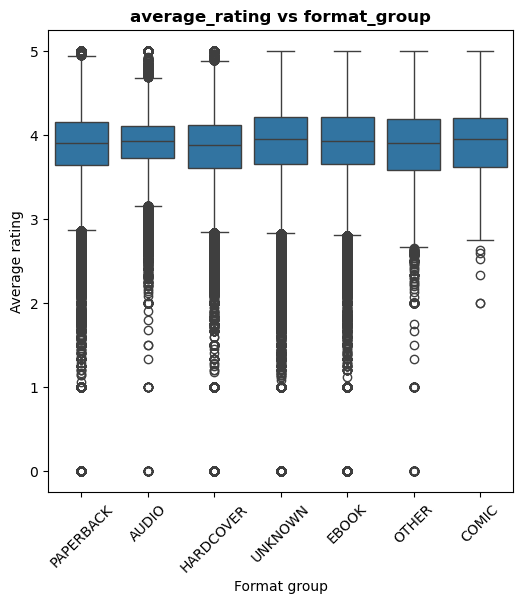

In [28]:
plot_boxplot_rating_por_formato(df_us_en)

Visualmente todas las lineas (meidanas) quedaron casi a la misma altura. Esto sugiere que Ee rating tipico de los libros es muy parecido independientemente del formato. 

Y como las cajas tienen tamaños similares, eso indica que la dispersion de los ratings tambien es parecida.

Ahora, como la cantidad de muestras por categoria es muy significativa, tambien hay que analizar los valores estadisitcos (de la tabla de arriba):

En cuanto al mean --> La diferencia entre el mas alto y el mas bajo es: 3.910 - 3.837 = 0.073. Entonces, si bien existen pequeñas diferencias entre categorias, los valores medios de average_rating son muy similares para todos los formatos que estamos analizando. Esto sugiere que el formato de publicacion no presenta una relacion fuerte con la valoracion promedio de los libros.

En cuanto al std --> Los audiolibros tienen una dispersion bastante menor. Esto podria indicar que los audiolibros suelen recibir ratings mas consistentes, o que hay menos titulos de muy baja valoración dentro de AUDIO.

### 3.4 "series"

In [29]:
df_us_en["series"].str.len().value_counts().sort_index()

series
0    1310737
1     563599
2      40949
3       7358
4       3223
Name: count, dtype: int64

La feature "series" contiene una lista. Si la lista esta vacia el libro no es parte de una saga. No tiene valores Nan o que no sean una lista. --> esto ultimo se mantiene con este nuevo dataset???

In [30]:
#is_series: feature binaria, true si es parte de una saga
df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
df_us_en = df_us_en.drop(columns = ["series"]) 

Creamos la feature is_series, que tiene "true" si el libro es parte de una saga (es decir el largo de la lista de la feature "series" es mayor a 0), "false" sino.

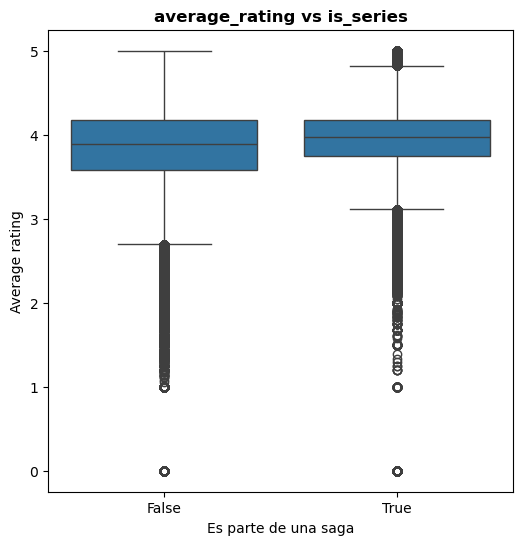

In [31]:
plot_boxplot_rating_por_is_series(df_us_en)

Los libros que pertenecen a una saga tienen ratings ligeramente mas altos --> La mediana de is_series = True esta un poco por encima de la de is_series = False

In [32]:
df_us_en.groupby("is_series")["average_rating"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
is_series,,,,
False,1310737,3.853077,3.89,0.591337
True,615129,3.953374,3.97,0.358998


La diferencia de medias es: 3.953 - 3.853 = 0.100, y la diferencia de medianas es: 3.97 - 3.89 = 0.08

Esto puede parecer poco, pero, como ya vimos antes, en Goodreads los ratings suelen concentrarse mucho entre 3.5 y 4.5.

Es por esto que, una diferencia de 0.10 puntos en un dataset de casi 2 millones de observaciones no es despreciable.

Ademas, la dispersión cambia bastante: std(False) = 0.591 y std(True)  = 0.359. --> Los libros que pertenecen a sagas tienen ratings mucho mas concentrados. Visualmente, esto tambien se veia en el boxplot: la caja de True es mas compacta; hay menos valores extremadamente bajos; los ratings estaban mas agrupados alrededor de 4. 

Posible explicacion --> Sesgo de supervivencia: Muchas sagas continuan publicandose porque: los primeros libros tuvieron exito; los lectores siguieron comprando; la comunidad de fans se consolido. Por lo tanto, los libros de sagas suelen partir de una base de lectores mas favorable.

### 3.5 "publication_year" y "num_pages"

In [33]:
df_us_en[["publication_year","num_pages"]].describe()
df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"],errors='coerce')
df_us_en[["publication_year","num_pages"]].describe()
print(df_us_en["num_pages"].isna().sum())
print(df_us_en["publication_year"].isna().sum())

708963
548371


Noto que hay que tratar con varios nan en publication year y num pages. Hay que decidir como tratar eso.

##### Analizando "num_pages"

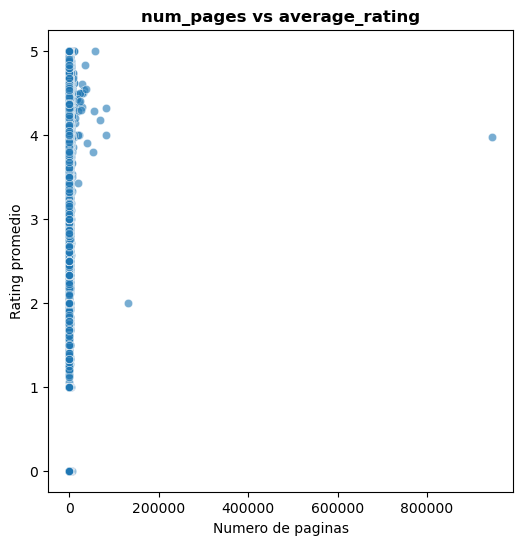

In [34]:
plot_scatte_rating_por_num_pages(df_us_en)

Definitvamente hay outliers -> consideramos que habria que eliminar los puntos que superan una cantidad ridicula de paginas

Vemos que para una misma aprox cantidad de hojas el rating varia muchismo (adopta casi todo los valores posibles) --> no sera una feature que por si sola determine mucho el target

Quiero cheqeuar el min y max de cantidad de hojas (porque no tendria sentido, por ejemplo, un libro con 0 hojas...)

In [35]:
print(df_us_en["num_pages"].max())
print(df_us_en["num_pages"].min())

945077.0
0.0


Definitivamente vamos a tener que eliminar outliers y valores ilogicos... 

##### Analizando "publication_year"

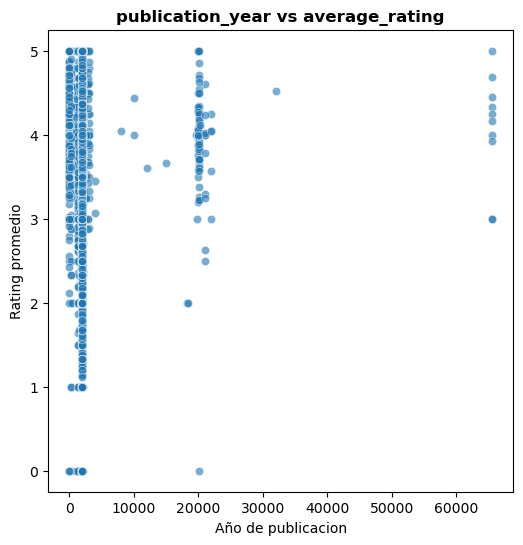

In [36]:
plot_scatte_rating_por_publication_year(df_us_en)

Al igual que con "num_pages", a esta escala, pareceria que la feature no es muy relevante para el target. Y posee MUCHOS mas outliers que "num_pages". Mas bien, son valores mal cargados, porque no tiene sentido que el año de publicacion sea mas grande que 2026...

Veamos en un escala mas chica (rango de años mas razonable):

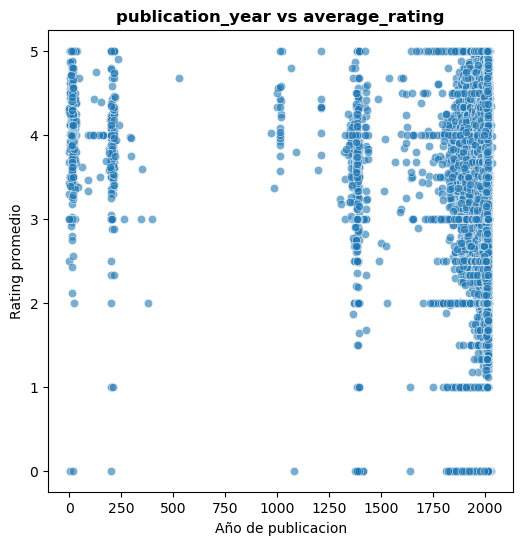

In [37]:
df_filtrado_publi_year = df_us_en[df_us_en["publication_year"] <= 2040]
plot_scatte_rating_por_publication_year(df_filtrado_publi_year)

Definitivamente a simple vista no se puede identificar una fuerte realcion entre el targte y esta variable, pero seguimos descubirendo posible outliers... --> Como son los titulos de tiene año de publicacion cerca de cero? Porque si son antiguos tendria sentido, pero sino, son datos mal registrados...

### 3.6 Buscando la feature "genero"

In [38]:
for i in range(5): #imprimo algunos ejemplos de las bibliotecas mas elegidas para guardar el libro
    print(f"Libro {i}")
    print(df_us_en["popular_shelves"].iloc[i])
    print()

Libro 0
[{'count': '3', 'name': 'to-read'}, {'count': '1', 'name': 'p'}, {'count': '1', 'name': 'collection'}, {'count': '1', 'name': 'w-c-fields'}, {'count': '1', 'name': 'biography'}]

Libro 1
[{'count': '2634', 'name': 'to-read'}, {'count': '160', 'name': 'fiction'}, {'count': '92', 'name': 'currently-reading'}, {'count': '25', 'name': 'contemporary-fiction'}, {'count': '22', 'name': 'owned'}, {'count': '19', 'name': 'book-club'}, {'count': '17', 'name': 'chick-lit'}, {'count': '16', 'name': 'friendship'}, {'count': '15', 'name': 'books-i-own'}, {'count': '12', 'name': 'novel'}, {'count': '12', 'name': 'general-fiction'}, {'count': '11', 'name': 'anita-diamant'}, {'count': '10', 'name': 'owned-books'}, {'count': '10', 'name': 'contemporary'}, {'count': '10', 'name': 'women'}, {'count': '8', 'name': 'adult'}, {'count': '7', 'name': 'default'}, {'count': '7', 'name': 'favorites'}, {'count': '7', 'name': 'didn-t-finish'}, {'count': '6', 'name': 'own-it'}, {'count': '6', 'name': 'librar

In [39]:
# #imprimo las estanterias mas populares
# chunks = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)
# contador = Counter()
# for chunk in tqdm(chunks):
#     for shelves in chunk["popular_shelves"]:
#         for shelf in shelves:
#             contador[shelf["name"]] += int(shelf["count"])
# contador.most_common(2000)
# #TODO: comentario de clara para clara: comentar este bloque antes de correr

Varias de estas estanterias no son generos (ej: to-read). En base a estos ejemplos, creo una funcion que detecta diferentes maneras de llamar a un mismo genero. Por ejemplo, "young-adult" y "ya" corresponden al mismo genero. Aparte, si un libro tiene como genero "historical-fiction" se podria decir que tiene como generos "historical" y fiction". Filtro estos diccionarios para extraer una lista de generos para cada libro. 

In [40]:
df_us_en["genres"] = df_us_en["popular_shelves"].apply(extraer_generos_libro)
sin_genero = (df_us_en["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero/len(df_us_en):.2f}%")

Porcentaje de libros sin genero: 12.35%


Una vez aplicada esta funcion, noto que el 12% de los libros no tienen genero. Viendo algunos libros, noto que de base el diccionario no tenia generos, no es que la funcion no esta detectando correctamente variantes de generos. 

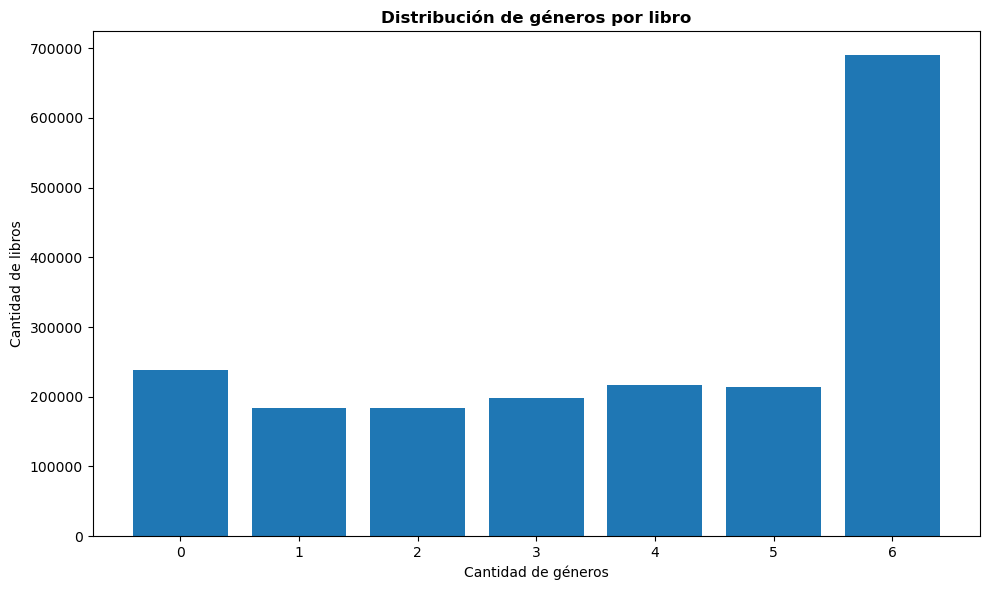

In [41]:
plot_cantidad_generos_por_libro(df_us_en)

En un primer momento, este grafico mostraba que habia libros con 18 generos. Varios de estos eran falsos positivos o ruido. Para evitar esto, elijo un maximo de 6 generos por libro.
Estas distribuciones resultan mucho mas razonables

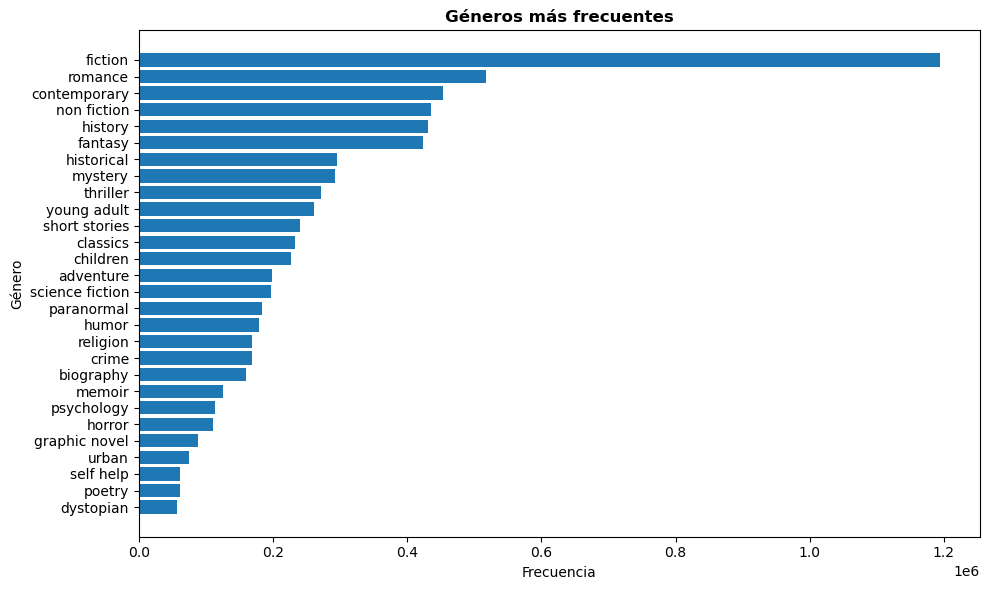

In [42]:
contador_generos = (df_us_en["genres"].explode().value_counts()) #.explode() separa los elementos de la lista
plot_generos_mas_frecuentes(contador_generos)

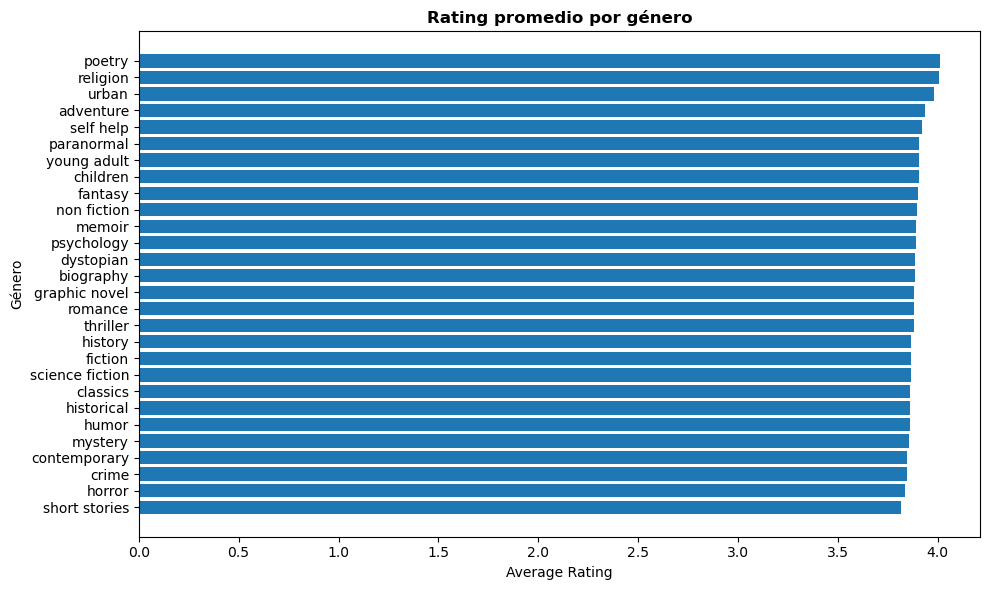

In [43]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"],errors="coerce")
plot_rating_por_genero(df_us_en)

Hay una leve diferencia entre el rating de los generos, pero esta permanece entre 3.7 y 4.

<Figure size 1200x600 with 0 Axes>

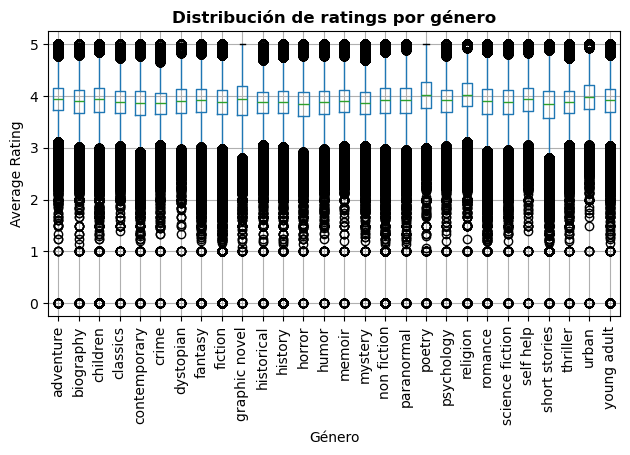

In [44]:
plot_boxplot_rating_por_genero(df_us_en)

### 3.7 "author"

In [45]:
#Creamos una nueva feature n_authors, que contiene la cantidad de autores de un libro
df_us_en.loc[:, "n_authors"] = df_us_en["authors"].apply(len)

print("Distribución de cantidad de autores por libro:")
print(f"\n% con 1 solo autor: {(df_us_en['n_authors'] == 1).mean():.1%}")
print(f"% con mas de 2 autores: {(df_us_en['n_authors'] >= 2).mean():.1%}")
print(f"% con 0 autores: {(df_us_en['n_authors'] == 0).mean():.1%}")

#DECISION: elimino los pocos libros que no tienen ningun autor (la lista de diccionarios esta vacia)
df_us_en = df_us_en[df_us_en["authors"].apply(len) > 0]
#comentario para sol: el 0.0% es enganioso, esta redondeado, si imprimis mas decimales va a aparecer 0.00001, ademas, seguro con todo el dataset va a aparecer algun libro mas sin autor

Distribución de cantidad de autores por libro:

% con 1 solo autor: 80.0%
% con mas de 2 autores: 20.0%
% con 0 autores: 0.0%


In [46]:
#Todos los roles que aparecen, con su frecuencia
roles = (df_us_en["authors"].explode().apply(lambda x: x["role"]).value_counts())
total_roles = roles.sum()
print("Frecuencia de cada rol:")

for role, count in roles[:20].items():
    if role != "":
        label = role 
    else: 
        label = ""
    print(f"  {label}: {count} ({count/total_roles:.1%})")

Frecuencia de cada rol:
  : 2182358 (82.6%)
  Illustrator: 92318 (3.5%)
  Contributor: 81001 (3.1%)
  Editor: 70273 (2.7%)
  Narrator: 38452 (1.5%)
  Translator: 31052 (1.2%)
  Illustrations: 26517 (1.0%)
  Introduction: 11932 (0.5%)
  Foreword: 10637 (0.4%)
  Artist: 6257 (0.2%)
  Translation: 5968 (0.2%)
  Reading: 5952 (0.2%)
  Writer: 5167 (0.2%)
  Creator: 3872 (0.1%)
  Photographer: 3645 (0.1%)
  Text: 3376 (0.1%)
  contributor: 3281 (0.1%)
  Foreword by: 2855 (0.1%)
  editor: 2360 (0.1%)
  narrator: 2252 (0.1%)


In [47]:
df_us_en["primer_es_vacio"] = df_us_en["authors"].apply(primer_tiene_role_vacio)

print("¿El primer autor de la lista tiene role vacío?")
print(df_us_en["primer_es_vacio"].value_counts(normalize=True))

¿El primer autor de la lista tiene role vacío?
primer_es_vacio
True     0.967719
False    0.032281
Name: proportion, dtype: float64


En base a estos analisis, decidio extraer el autor principal de la siguiente manera:
Noto que si el valor de "role" esta vacio (que es la mayoria de los casos), es el autor (en sentido de escritor). En caso de que haya varios, devuelvo el primero, el principal.

In [48]:
df_us_en["author_id_principal"] = df_us_en["authors"].apply(extraer_autor_principal)

In [49]:
# # Tomo el primer autor de cada libro
# df_us_en["author_id"] = df_us_en["authors"].apply(lambda x: x[0]["author_id"] if isinstance(x, list) and len(x) > 0 else None)

In [50]:
top_autores = df_us_en["author_id_principal"].value_counts().head(10)
print(top_autores)

author_id_principal
123715     2713
5158478    2420
3780       2164
3389       2049
947        1856
625        1617
239579     1494
2448       1397
1265       1263
1654       1118
Name: count, dtype: int64


In [51]:
for autor_id in top_autores.index:
    print(f"\nAutor {autor_id}")
    print(df_us_en[df_us_en["author_id_principal"] == autor_id]["title"].head(20).to_list())


Autor 123715
['A Murder is Announced', '4:50 From Paddington', 'The Mysterious Affair at Styles (Hercule Poirot Book 1)', "Mrs. McGinty's Dead", 'Third Girl (Hercule Poirot, #35)', 'Cat Among the Pigeons', 'Un Gato en el Palomar', 'Death Comes as the End', 'Death In The Clouds', 'Murder on the Links', "Mrs. McGinty's Dead: A BBC Radio 4 Full-Cast Dramatisation", 'The Chocolate Box', 'Poirot Investigates', 'Cards on the Table (Hercule Poirot #15)', "Dead Man's Folly (Hercule Poirot, #31)", "Why Didn't They Ask Evans?", 'Det Forstenede Ansigt', 'Crooked House', 'Meurtre au champagne', 'Partners in Crime (Tommy and Tuppence #2)']

Autor 5158478
['Stress Less and Enjoy Each Day: 10 Principles to Help You Reduce Tension and Enjoy More Peace', 'Koine Greek New Testament', 'Lawmen & Outlaws', 'The Táin', 'The Passion of Mademoiselle S.: Letters to a Lover', 'Vikram and the Vampire: Classic Hindu Tales of Adventure Magic and Romance', "Webster's Compact Rhyming Dictionary", 'The Complete I Ch

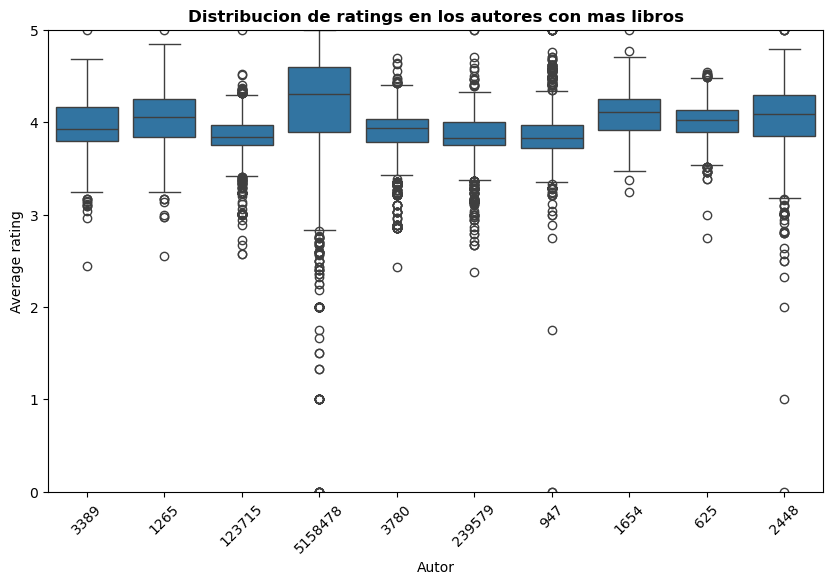

In [53]:
autores_top = top_autores.index
df_top = df_us_en[df_us_en["author_id_principal"].isin(autores_top)]
plot_boxplot_rating_por_autor_frecuent(df_top, "Distribucion de ratings en los autores con mas libros")

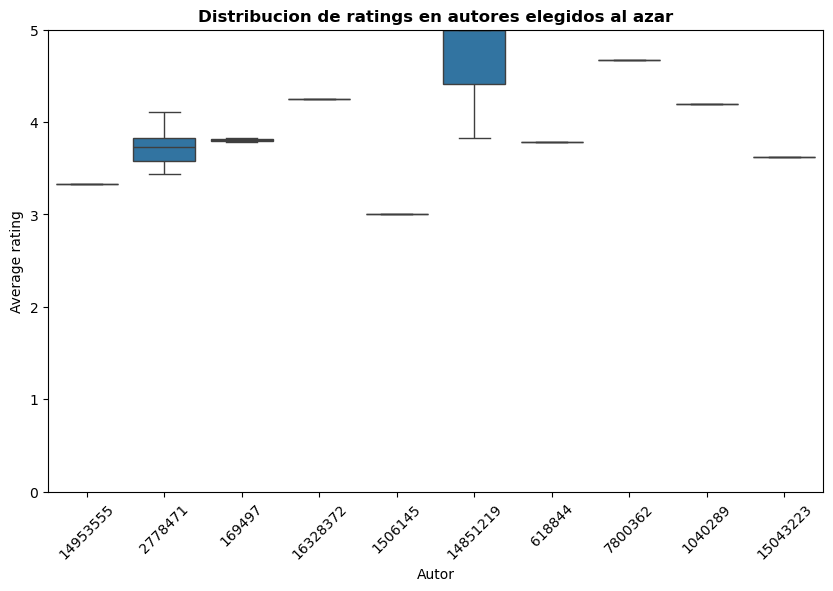

In [54]:
autores_random = df_us_en["author_id_principal"].drop_duplicates().sample(10, random_state = 42)
df_random = df_us_en[df_us_en["author_id_principal"].isin(autores_random)]
plot_boxplot_rating_por_autor_frecuent(df_random, "Distribucion de ratings en autores elegidos al azar")

Cuando tomamos autores que no publicaron tantos libros observamos resultados mas dispersos.

### 3.8 Libros repetidos

In [56]:
print("Filas totales:", len(df_us_en))
print("Duplicados por título:")
print(df_us_en["title"].duplicated().sum())

Filas totales: 1925859
Duplicados por título:
529280


In [57]:
duplicados = df_us_en[df_us_en["title"].duplicated(keep = False)]
cantidad_por_titulo = duplicados.groupby("title").size().sort_values(ascending = False)
print(cantidad_por_titulo.head(20))

title
Selected Poems                      299
Pride and Prejudice                 298
Jane Eyre                           258
Wuthering Heights                   256
Dracula                             227
Frankenstein                        206
A Christmas Carol                   190
The Great Gatsby                    177
The Picture of Dorian Gray          174
Emma                                168
Great Expectations                  162
The Secret Garden                   161
Sense and Sensibility               153
Treasure Island                     148
Alice's Adventures in Wonderland    141
Little Women                        134
Persuasion                          133
The Scarlet Letter                  130
Anna Karenina                       130
A Tale of Two Cities                129
dtype: int64


Los duplicados pueden indicar diferentes ediciones de un mismo libro. Esto tiene sentido ya que los libros mencionados son muy conocidos, tiene sentido que hayan sido publicados multiples veces.

Veamos como ejemplo un caso especifico de los que aparecen ahi, para analizar el problema en mas detalle:

In [63]:
df_us_en[df_us_en["title"] == "Pride and Prejudice"][["title", "authors", "publisher", "publication_year", "num_pages", "format_group", "average_rating", "ratings_count"]].head(20)

,title,authors,publisher,publication_year,num_pages,format_group,average_rating,ratings_count
6607,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",YBM Si-sa,2006.0,239.0,PAPERBACK,4.25,710
12730,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Arcturus,2009.0,352.0,PAPERBACK,4.25,265
27187,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sterling Publishing,2012.0,325.0,HARDCOVER,4.25,10
59852,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Public Domain,2010.0,472.0,EBOOK,4.25,3
94128,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Signet Classics,1961.0,NaN,PAPERBACK,4.25,30
107186,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Penguin,NaN,346.0,UNKNOWN,4.25,147
108830,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Recorded Books,2006.0,692.0,AUDIO,4.25,7
110494,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Signet Classic,1996.0,324.0,UNKNOWN,4.25,360
145723,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sourcebooks,2010.0,258.0,EBOOK,4.25,41
146272,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",BBC Books,2014.0,1.0,AUDIO,4.25,5


Ahora, veamos cuantas muestras comparten el mismo titulo Y el mismo autor (porque si solo coinciden en titulo, pero su autor es diferente, entonces son obras distintas):

In [64]:
duplicados = (df_us_en.groupby(["title", "author_id_principal"]).size().sort_values(ascending=False))
duplicados.head(20)

title                             author_id_principal
Pride and Prejudice               1265                   293
Jane Eyre                         1036615                253
Wuthering Heights                 4191                   248
Dracula                           6988                   214
Frankenstein                      11139                  198
A Christmas Carol                 239579                 181
The Great Gatsby                  3190                   172
The Picture of Dorian Gray        3565                   171
Great Expectations                239579                 157
The Secret Garden                 2041                   154
Emma                              1265                   153
Sense and Sensibility             1265                   148
Treasure Island                   854076                 141
Alice's Adventures in Wonderland  8164                   139
Persuasion                        1265                   132
Little Women                   

Fusionamos los libros repetidos:

In [ ]:
#1. Tenemos que tener aseguro el autor para cada muestra (seccion 3.7)
#2. Escribimos el titulo en minusculas para que sean comparables entre muestras (por si es el mismo nombre, pero con algo diferente):
df_us_en["title_key"] = (df_us_en["title"].str.lower().str.strip())
df_us_en["ratings_count"] = pd.to_numeric(df_us_en["ratings_count"], errors="coerce")
df_us_en = (df_us_en.groupby(["title_key", "author_id_principal"], as_index = False).apply(fusionar_libros).reset_index(drop = True))

TypeError: '>' not supported between instances of 'str' and 'int'

### 3.9 Correlacion entre features

In [ ]:
#Realizo las transformaciones necesarias:
df_us_en = multi_binarizer_format(df_us_en) #multi binarizer de format
df_us_en = multi_binarizer_genre(df_us_en) #multi binarizer de genero
df_us_en = one_hot_language(df_us_en) #one hot de language_code

In [ ]:
#CHEQUEAR CUALES SON LOS NOM

In [ ]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", "AUDIO", "COMIC", "EBOOK", "HARDCOVER", "OTHER", "PAPERBACK", "UNKNOWN", "en", "eng", "en-us", "en-gb", "en-ca", "enm", "ang", "sco", "gem"] + generos

#correlacion con el target
corr_rating = (df_us_en[features + ["average_rating"]].corr(numeric_only=True)["average_rating"].sort_values())
plot_correlacion_features(corr_rating)

Por si solas, estas features no aportan mucha informacion al modelo. Sin embargo, podemos intentar con algunas combinaciones:
- young adult * romance
- young adult * fantasy
- mystery * thriller
- len(generos)

### 3.10 "publisher"

Abro el archivo filtrado:

In [ ]:
# chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)

# chunk_list33 = []
# for chunk in chunks33:
#     chunk_list33.append(chunk)

# df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
# print(df_us_en_1_filtro.shape)
# #TODO: comentario de clara para clara: comentar este bloque antes de correr

(1146363, 15)


In [ ]:
top_publishers = df_us_en["publisher"].value_counts().head(10)
print(top_publishers)

publisher
                                               50545
Createspace Independent Publishing Platform    16171
Createspace                                     9347
Harlequin                                       8285
HarperCollins                                   7030
Penguin Books                                   6656
Oxford University Press, USA                    6320
Vintage                                         6061
Berkley                                         4833
Ballantine Books                                4802
Name: count, dtype: int64


In [ ]:
publishers_unique = df_us_en["publisher"].unique()

In [ ]:
print(len(publishers_unique))

114234


### 3.11 Valores NaN 

In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df_us_en.isna().sum(),
    "missing_pct": df_us_en.isna().mean() * 100,
    "empty_string_count": (df_us_en == "").sum()
})
print(missing_summary)

                    missing_count  missing_pct  empty_string_count
text_reviews_count              0          0.0                   0
language_code                   0          0.0              586128
popular_shelves                 0          0.0                   0
average_rating                  0          0.0                   0
similar_books                   0          0.0                   0
description                     0          0.0               87649
publication_year                0          0.0                   0
ratings_count                   0          0.0                   0
title                           0          0.0                   4
authors                         0          0.0                   0
publisher                       0          0.0               50545
num_pages                       0          0.0                   0
estrellas                       0          0.0                   0
format_group                    0          0.0                

Analizamos los valores faltantes de la feature language_code:

In [ ]:
mask_lang = df_us_en["language_code"].fillna("").str.strip().eq("")
muestras_vacias_lang = df_us_en[mask_lang]
print(muestras_vacias_lang.shape)
display(muestras_vacias_lang.head(20))

(586128, 15)


,text_reviews_count,language_code,popular_shelves,average_rating,similar_books,description,publication_year,ratings_count,title,authors,publisher,num_pages,estrellas,format_group,is_series
0,1,,"[{'count': '3', 'name': 'to-read'}, {'count': ...",4.00,[],,1984,3,W.C. Fields: A Life on Film,"[{'author_id': '604031', 'role': ''}]",St. Martin's Press,256,4,PAPERBACK,False
3,7,,"[{'count': '56', 'name': 'to-read'}, {'count':...",4.13,[],"Relates in vigorous prose the tale of Aeneas, ...",2006,46,The Aeneid for Boys and Girls,"[{'author_id': '3041852', 'role': ''}]",Yesterday's Classics,162,4,PAPERBACK,False
4,6,,"[{'count': '515', 'name': 'to-read'}, {'count'...",4.22,"[948696, 439885, 274955, 12978730, 372986, 216...","To Kara's astonishment, she discovers that a p...",2009,98,All's Fairy in Love and War (Avalon: Web of Ma...,"[{'author_id': '19158', 'role': ''}]",Seven Seas,216,4,PAPERBACK,True
5,39,,"[{'count': '961', 'name': 'to-read'}, {'count'...",3.81,"[287151, 1104760, 1172822, 440292, 287082, 630...","Wisdom, humor, and dark observations by the fo...",2000,986,The Devil's Notebook,"[{'author_id': '2983296', 'role': ''}, {'autho...",Feral House,147,4,PAPERBACK,False
6,15,,"[{'count': '159', 'name': 'to-read'}, {'count'...",3.93,"[439108, 522621, 116770, 1275927, 6202655, 840...","London, 1196. At the command of Richard the Li...",2009,186,"Crowner Royal (Crowner John Mystery, #13)","[{'author_id': '37778', 'role': ''}]",Simon & Schuster UK,400,4,HARDCOVER,True
7,615,,"[{'count': '4248', 'name': 'to-read'}, {'count...",3.98,"[614054, 272343, 824934, 581383, 93598, 638689...",It's 1953 and 11-year-old Penny dreams of a su...,2006,6949,Penny from Heaven,"[{'author_id': '137561', 'role': ''}]",Random House Books for Young Readers,288,4,HARDCOVER,False
11,9,,"[{'count': '7615', 'name': 'to-read'}, {'count...",3.48,"[10596, 11532, 32453, 32430, 32640, 948244, 69...","Unabridged CDs, 25 CDs, 30 hours\nRead by TBA\...",2010,45,The Tommyknockers,"[{'author_id': '3389', 'role': ''}, {'author_i...",Penguin Audio,1,3,AUDIO,False
14,10,,"[{'count': '13', 'name': 'to-read'}, {'count':...",3.98,"[12505811, 12349615, 11890677, 13611511, 13112...",When single mother Danielle Jordan discovers h...,2011,71,Holding On,"[{'author_id': '5054653', 'role': ''}]",Createspace,290,4,PAPERBACK,False
17,17,,"[{'count': '429', 'name': 'classics'}, {'count...",3.57,"[1109271, 893023, 572268, 379255, 111723, 9904...","Hemingway's classic novel about contraband, in...",2006,45,To Have and Have Not,"[{'author_id': '1455', 'role': ''}, {'author_i...",Simon Schuster Audio,5,4,AUDIO,False
18,1,,"[{'count': '62', 'name': 'to-read'}, {'count':...",4.00,[],"WINNER, Business: Personal Finance/Investing, ...",2014,4,Investor Behavior: The Psychology of Financial...,"[{'author_id': '53167', 'role': ''}, {'author_...",Wiley,640,4,EBOOK,False


In [ ]:
#Para que los resultados sean reproducibles
DetectorFactory.seed = 42
# Tomamos una muestra
sample = (df_us_en[df_us_en["language_code"] == ""].sample(1000, random_state = 42).copy())
sample["detected_language"] = sample.apply(detectar_language_code, axis=1)
print(sample["detected_language"].value_counts(normalize=True).mul(100).round(2))

detected_language
en    96.3
es     0.9
fr     0.6
de     0.4
ar     0.3
cy     0.2
id     0.2
nl     0.2
sv     0.1
tl     0.1
sq     0.1
hr     0.1
no     0.1
vi     0.1
da     0.1
it     0.1
sl     0.1
Name: proportion, dtype: float64


In [ ]:
df_us_en.loc[df_us_en["language_code"] == "", "detected_language"] = (df_us_en.loc[df_us_en["language_code"] == ""].apply(detectar_language_code, axis=1))
print("Filas antes:", len(df_us_en))
# Conservamos las muestras con language_code original y != "", y filas con ese valor vacío, pero detectado como ingles:
df_us_en = df_us_en[(~(df_us_en["language_code"] == "")) | ((df_us_en["language_code"] == "") & (df_us_en["detected_language"] == "en"))]

# Completamos con "eng" los que fueron detectados como ingles:
df_us_en.loc[(df_us_en["language_code"] == "") &(df_us_en["detected_language"] == "en"), "language_code"] = "eng"

# Eliminamos la columna auxiliar creada:
df_us_en.drop(columns = ["detected_language"], inplace = True )

print("Filas después:", len(df_us_en))
print(df_us_en = ["language_code"].value_counts())


Filas antes: 1146363
Filas después: 1117279
language_code
eng      1020325
en-US      58837
en-GB      36633
en-CA       1264
en           164
enm           35
ang           10
sco            9
gem            2
Name: count, dtype: int64


Analizo los valores faltantes de la feature "description": 

Como vamos a hacerles embeddings, puedo hacerle el embedding a un string vacio. Entonces, lo dejamos asi.

In [ ]:
(df_us_en["description"].fillna("").str.split().str.len().quantile([0.25, 0.5, 0.75, 0.9, 0.95]))

0.25     67.0
0.50    123.0
0.75    179.0
0.90    242.0
0.95    290.0
Name: description, dtype: float64

En base a la longitud de los valores y al hecho de que esta tecnica es capaz de capturar el signficado del texto (coloca en el espacio vectorial a palabras con significados similares juntas), decidimos suar embeddings en vez de TF-IDF

Analizando los valores flatantes de "publisher":

In [ ]:
df_us_en["publisher"].nunique()

107127

In [ ]:
df_us_en["publisher"] = (df_us_en["publisher"].replace("", "UNKNOWN_PUBLISHER"))

## 4. Continuamos el preprocesamiento (se empezo un poco antes del EDA):

Comienzo por eliminar los outliers de "publication_year" y "number_pages":

In [ ]:
#Las features "publication_year" y "num_pages" presetan valores NaN y algunos registros con valores extremos (ilogicos). 
#Como creemos que no hay una estrategia de imputacion que permita estimar esos valores de forma confiable y acorde a cada muestra en particular
#(la media o mediana no tendrian mucho sentido en estos casos), decidimos quedarnos solamente con las muestras que poseen años de publicacion 
#comprendidos entre 1440 (comienzo de la impresion) y 2026, y cantidad de paginas entre 1 y 10000. Este filtrado elimino simultaneamente aquellos 
#datos que poseian algun valor faltant para alguna de estas dos caracterisitcas (este porcentaje de muestras es insignificante en comapracion
# a la cantidad total de datos que se posee).

mask = df_us_en['publication_year'].between(1440, 2026) & df_us_en["num_pages"].between(1, 10000) #1440 es el año en que se invento la impresion
df_us_en = df_us_en[mask]


In [ ]:
#df_entrenamiento = limpiar_features_no_necesarias(df)

KeyError: "['format_AUDIO', 'format_COMIC', 'format_EBOOK', 'format_HARDCOVER', 'format_OTHER', 'format_PAPERBACK', 'format_UNKNOWN'] not in index"

Ahora, tenemos que eliminar las observaciones poco confiables. Es decir, aquellas que poseen rating_count bajo (ya que indica que poseen un average_rating volatil):

In [ ]:
bins_s4 = [0,1,2,5,10,20,50,100,500,np.inf]

df_us_en.groupby(pd.cut(df_us_en["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])

/var/folders/vz/dvp73rjn6bb_xqcp58j9_h900000gn/T/ipykernel_1216/2166363915.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_us_en_1_filtro.groupby(pd.cut(df_us_en_1_filtro["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])


,count,mean,std
ratings_count,,,
"(0.0, 1.0]",57911,3.899299,0.884761
"(1.0, 2.0]",47734,3.928565,0.707486
"(2.0, 5.0]",107666,3.926907,0.579613
"(5.0, 10.0]",120613,3.903313,0.484805
"(10.0, 20.0]",146259,3.876027,0.424697
"(20.0, 50.0]",202334,3.854788,0.375647
"(50.0, 100.0]",132203,3.848722,0.345317
"(100.0, 500.0]",190091,3.871453,0.317285
"(500.0, inf]",107055,3.937009,0.279153


Como sospechabamos, a medida que rating_count aumenta, disminuye el desvio estandar (la dispersion) del rating.

La caida mas fuerte ocurre en el rango de rating_count comenzando en (0.0, 1.0] hasta el de (5.0, 10.0]. Luego de ese rango, sigue bajando el std, pero mucho mas gradualmente. 

In [ ]:
len(df_us_en)

1117279

In [ ]:
len(df_us_en[df_us_en["ratings_count"] >= 10])

798118

Si hicieramos el corte en 10, perderiamos un 29% de mustras, aproximadamente (((1117279 - 798118) / 1117279) * 100).

In [ ]:
len(df_us_en[df_us_en["ratings_count"] >= 20])

642982

En cambio, si hicieramos el corte en 20, perderiamos un 42% de mustras, aproximadamente (((1117279 - 642982) / 1117279) * 100).

Y si vemos la tabla de progreso de estabilidad, observamos que (10.0, 20.0] tiene un std ~ 0,42% y (20.0, 50.0] tiene un std ~ 0,37%. Es decir, que hay un 0,05% de mejora, lo cual no nos parece tan significante como para perder 155136 muestras adicionales (798118 - 642982).

In [ ]:
df_us_en = df_us_en[df_us_en["ratings_count"] >= 10]

Aplicamos el filtro para la feature "genero":

In [ ]:
df_us_en["genres"] = df_us_en["popular_shelves"].apply(df_us_en)
sin_genero_s4 = (df_us_en["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero_s4/len(df_us_en):.2f}%")

Porcentaje de libros sin genero: 1.80%


Como el porcentaje de muestras que poseen su feture genero vacia es muy bajo, podemos dejar el valor tal cual como esta ([]) (en vez de generar otra categoria artificial llamada, por ejemplo, "unknown") y usar nuestra MultiLabelBinarizer, la cual simplemente va a generar una lista de ceros.

Tambien queremos hacer generar una nueva feature llamada cantidad_generos, la cual indicara en cuantos generos se clasifico al libro (para ver si tiene alguna relaicon con el rating o no):

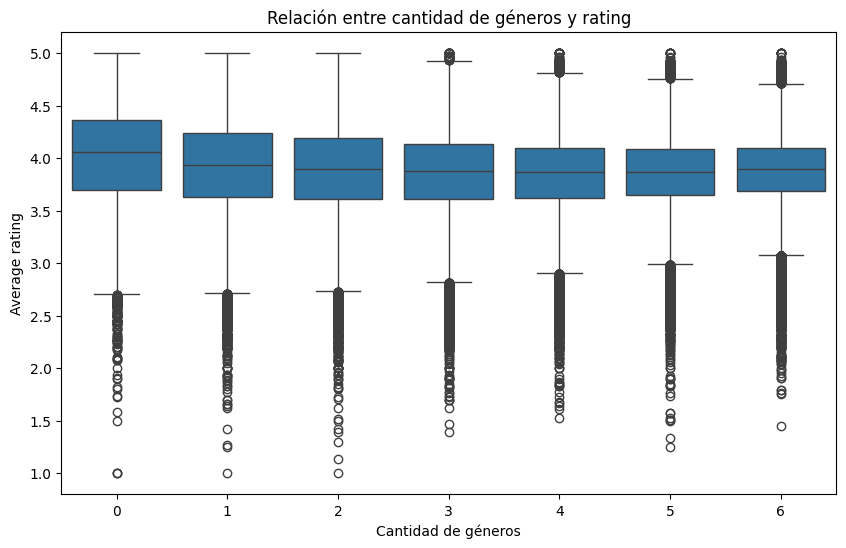

In [ ]:
df_us_en["cantidad_generos"] = df_us_en["genres"].apply(len)
plot_boxplot_rating_por_cant_generos(df_us_en)

Mirando el boxplot, no parece haber una relacion fuerte entre la cantidad de generos asignados a una muestra y su average_rating. Excepto por el caso en el que las muestras poseen la lista de generos vacias, el resto de las opciones parecen tener medianas muy parecidas. 

En conclusion, en base a este grafico, creemos que la cantidad de generos probablemnte tenga una correlacion muy baja con el rating, pero tal vez los generos especificos si aporten mas al target. 

Analisis para ver si es necesario hacer split por autores:

In [ ]:
# --- 1. Diagnóstico rápido: cuántos autores son "únicos" (1 solo libro) --- 
autor_counts = df_us_en.groupby("author_id")["estrellas"].count()
print(f"Autores totales: {autor_counts.shape[0]}") 
print(f"Autores con 1 solo libro: {(autor_counts == 1).sum()} " f"({(autor_counts == 1).mean():.1%})") 
print(f"Autores con 2+ libros: {(autor_counts > 1).sum()} " f"({(autor_counts > 1).mean():.1%})") 
print(f"Libros que pertenecen a un autor con 2+ libros: {df_us_en['author_id'].map(autor_counts).gt(1).mean():.1%}")

Autores totales: 217236
Autores con 1 solo libro: 123911 (57.0%)
Autores con 2+ libros: 93325 (43.0%)
Libros que pertenecen a un autor con 2+ libros: 84.5%


## 5. Splitting:

In [ ]:
#splitting estratificado basico
#df_dev, df_test = train_test_split(df_us_en, test_size = 0.2, stratify = df_us_en["estrellas"], random_state = 42)
#df_train, df_val = train_test_split(df_dev, test_size = 0.2, stratify = df_dev["estrellas"], random_state = 42)

In [ ]:
df_train, df_val, df_test = split_estratificado_autor(df_us_en, test_size = 0.15, val_size = 0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df_us_en):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df_us_en):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df_us_en):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize = True).sort_index())